# Stage 2 - Subsequence & Transition Models (k-grams + Markov chains)

**Goal.** Test `TransitionModel`: describe sessions by the short patterns (k-grams) they contain, cluster them, and profile every cluster with a first-order Markov chain to read flows, entry points, drop-offs, conversion bottlenecks and a representative journey.

### Why each method was chosen (for the project documentation)

| Component | Choice | Why | Main limitation |
|---|---|---|---|
| Session representation | **k-gram counts** (sparse vectors) | Captures local order without the O(L^2) alignment of Levenshtein; counts beat presence/unigrams (Wang et al., 2016/17); vectors allow clustering without an N x N matrix | Order only inside a window of k events |
| Distance | **cosine** (also angular, euclidean) | Compares *which patterns* a session uses, not how long it is; angular is a true metric | Cosine violates the triangle inequality |
| Clustering A | **k-medoids (PAM) on the k-gram distance** | Same algorithm as Stage 1, so only the *distance* changes: a controlled comparison; real prototype sessions | O(N^2) memory |
| Clustering B | **spherical k-means** on the sparse vectors | Linear in N, no distance matrix: answers the scalability question | Centres are averages, not real sessions |
| Profile | **First-order Markov chain per cluster** | Interpretable probabilities; heatmaps avoid "spaghetti" diagrams (Zhao 2015, Bar-El 2026) | Memoryless assumption |
| Drop-off / entry | Transitions to `<END>` / from `<START>` | Boundary tokens turn churn and entry points into ordinary matrix cells | Needs complete sessions |
| Bottlenecks | **Absorption probability** of reaching `purchase` | Turns the chain into a conversion estimate per state | Assumes the chain is a good model |
| Representative path | **Viterbi, max log-likelihood, length >= median** | Unconstrained best path is always the shortest one (bias); the bound removes it (Bar-El 2026) | Path may not exist in the data |
| Validation | **ARI / purity** (known groups), **silhouette** (internal) | Silhouette alone cannot say whether the right groups were found | ARI needs ground truth |

Because the real dataset appears random, every method is first checked on a **control dataset with planted structure**.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sys
from pathlib import Path

# Add v0.2/ root to sys.path so `journey_analyzer` imports cleanly from notebooks/
PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from journey_analyzer import TransitionModel, BaselineAligner
from journey_analyzer.evaluation import adjusted_rand_index, cluster_purity
from journey_analyzer.transitions import (START, END, extract_kgrams, build_kgram_matrix,
                                          pairwise_kgram_distances, spherical_kmeans)
from journey_analyzer.visualization import plot_transition_matrix, plot_dropoff_rates

## 1. Load the real data (same preprocessing as before, compact)
Sessions = `(UserID, SessionID)` groups sorted by time, keeping 2 events up to the 99th length percentile.

In [2]:
df = pd.read_parquet("../../data/processed/mkechinov_sessions.parquet")

# Parquet devuelve arrays de numpy: los pasamos a listas de strings
seqs = df["enriched_events"].apply(lambda x: [str(e).strip().lower() for e in x])
lens = seqs.str.len()

keep = (lens >= 2) & (lens <= np.percentile(lens, 99))
sequences = seqs[keep].tolist()
outcomes = df.loc[keep, "outcome"].tolist()        # alineado con `sequences`

print(len(df), "sesiones en el archivo ->", len(sequences), "tras el filtro")
print("eventos:", pd.Series([e for s in sequences for e in s]).value_counts().to_dict())
print("outcome:", pd.Series(outcomes).value_counts().to_dict())
print(lens.describe().round(1))

13776641 sesiones en el archivo -> 8639148 tras el filtro


MemoryError: Unable to allocate 419. MiB for an array with shape (54881295,) and data type int64

## 2. Control dataset: three behaviours generated by different Markov chains
Unlike the template-based control of Stage 1, here the groups differ in their *dynamics* (what follows what), which is exactly what k-grams and Markov chains should detect. The groups share events (login, page_view), so the task is not trivial.
- **buyer**: product_view -> add_to_cart -> purchase.
- **browser**: loops over page_view / click, never adds to cart.
- **bouncer**: enters and leaves after one or two pages.

In [ ]:
CHAINS = {
    "buyer": {"<S>": {"login": 1.0}, 
              "login": {"product_view": 0.8, "page_view": 0.2},
              "page_view": {"product_view": 0.8, "click": 0.2},
              "click": {"product_view": 0.7, "END": 0.3},
              "product_view": {"add_to_cart": 0.6, "product_view": 0.2, "page_view": 0.2},
              "add_to_cart": {"purchase": 0.8, "product_view": 0.2},
              "purchase": {"logout": 0.7, "END": 0.3},
              "logout": {"END": 1.0}},
    "browser": {"<S>": {"login": 0.5, "page_view": 0.5}, #loops over page_view/click
                "login": {"page_view": 1.0},
                "page_view": {"click": 0.5, "page_view": 0.25, "product_view": 0.15, "END": 0.1},
                "click": {"page_view": 0.6, "click": 0.3, "END": 0.1},
                "product_view": {"page_view": 0.7, "click": 0.2, "END": 0.1}},
    "bouncer": {"<S>": {"login": 0.6, "page_view": 0.4}, # leaves after one or two pages
                "login": {"page_view": 0.7, "logout": 0.3},
                "page_view": {"END": 0.6, "logout": 0.4},
                "logout": {"END": 1.0}},
}

def sample_session(chain, rng, max_len=20):
    seq, state = [], "<S>"
    while len(seq) < max_len:
        options = chain[state]
        state = str(rng.choice(list(options), p=list(options.values())))
        if state == "END":
            break
        seq.append(state)
    return seq

rng = np.random.default_rng(0)
ctrl, truth = [], []
for name, chain in CHAINS.items():
    for _ in range(200):
        ctrl.append(sample_session(chain, rng)); truth.append(name)
perm = rng.permutation(len(ctrl))
ctrl = [ctrl[i] for i in perm]; truth = np.array(truth)[perm]
print(len(ctrl), "sessions | mean length", round(np.mean([len(s) for s in ctrl]), 1))
for name in CHAINS:
    ex = next(s for s, t in zip(ctrl, truth) if t == name)
    print(f"{name:8s} example: {ex}")

600 sessions | mean length 6.1
buyer    example: ['login', 'product_view', 'add_to_cart', 'purchase']
browser  example: ['page_view', 'click', 'page_view']
bouncer  example: ['login', 'page_view']


Planted control dataset with 600 sessions shuffled (200 per "user type"). Later we are hidding this "truth" labels; and check wether the transition models are separating the data

## 3. k-grams: what a session looks like as a vector
With `<START>`/`<END>` boundaries, a session also encodes how it *begins* and *ends*.

In [ ]:
session = ["login", "page_view", "page_view", "purchase"]
print("k=2 grams:", extract_kgrams([START, *session, END], 2))

X_demo, grams = build_kgram_matrix([session, ["login", "page_view", "logout"]], k=2)
pd.DataFrame(X_demo.toarray(), columns=[" > ".join(g) for g in grams], index=["session A", "session B"]).T

k=2 grams: [('<START>', 'login'), ('login', 'page_view'), ('page_view', 'page_view'), ('page_view', 'purchase'), ('purchase', '<END>')]


,session A,session B
<START> > login,1.0,1.0
login > page_view,1.0,1.0
page_view > page_view,1.0,0.0
page_view > purchase,1.0,0.0
purchase > <END>,1.0,0.0
page_view > logout,0.0,1.0
logout > <END>,0.0,1.0


A = [1, 1, 1, 1, 1, 0, 0]
B = [1, 1, 0, 0, 0, 1, 1]

And then these vectors are compared... based on the presence of the different transitios based on the evets alphabet.

A session becomes a sparse vector of pattern counts. Two sessions are similar if they use the same patterns, independent of where in the session they appear.

## 4. Sanity check of the three distances on hand-made sessions
`cosine` and `angular` compare patterns and ignore length; `euclidean` on raw counts grows with length. Identical sessions must be 0 and sessions sharing nothing must be 1 (cosine).

In [ ]:
a  = ["login", "page_view", "click", "purchase"]
a_long = a * 5                                                   # same pattern, 5x longer
c  = ["logout", "add_to_cart", "add_to_cart"]                    # shares nothing with a
tm_demo = {m: TransitionModel(k=1, metric=m, add_boundaries=False).fit_kgrams([a, a, a_long, c]) for m in ("cosine", "angular", "euclidean")}
rows = []
for m, t in tm_demo.items():
    D = t.fit_distance_matrix()
    rows.append({"metric": m, "a vs a": D[0, 1], "a vs a x5 (longer)": D[0, 2], "a vs c (disjoint)": D[0, 3]})
pd.DataFrame(rows).set_index("metric").round(3)

,a vs a,a vs a x5 (longer),a vs c (disjoint)
metric,,,
cosine,0.0,0.0,1.0
angular,0.0,0.0,1.0
euclidean,0.0,8.0,3.0


This shows the trade-off in the choice of distance. Cosine compares the mix of patterns; euclidean is sensitive to session length. Angular gives the same ordering as cosine but is a true metric (cosine can break the triangle inequality).

This is different from Levenshtein Distance: in this case the length of the sequences does not matter that much anymore, BUT the what happends between events does.

## 5. Choosing k with two controls
Larger k keeps more order but makes the vocabulary explode; k=1 (single events) keeps no order at all. Two controls separate these effects:
- **Composition control** (section 2): groups differ mostly in which events they contain.
- **Order-only control**: groups contain exactly the same events, in opposite order (forward vs reversed funnel). A bag of events cannot tell them apart; only order-aware methods can.

A good k must work on both. We use the Adjusted Rand Index (ARI) against the known groups, and Levenshtein as the order-aware reference.

In [ ]:
order_templates = {"forward": ["page_view", "click", "product_view", "add_to_cart", "purchase"],
                   "reverse": ["purchase", "add_to_cart", "product_view", "click", "page_view"]}
rng_o = np.random.default_rng(5)
ctrl_order, truth_order = [], []
for name, t in order_templates.items():
    for _ in range(150):
        s = [e for e in t if rng_o.random() > 0.1]                   # each event dropped with prob 0.1
        ctrl_order.append(s if len(s) >= 2 else list(t)); truth_order.append(name)
truth_order = np.array(truth_order)

rows = []
for k in range(1, 6):
    t1 = TransitionModel(k=k).fit_kgrams(ctrl);       t1.cluster(3, "kmedoids")
    t2 = TransitionModel(k=k).fit_kgrams(ctrl_order); t2.cluster(2, "kmedoids")
    Xr, _ = build_kgram_matrix(sequences[:2000], k)
    rows.append({"k": k, "vocab (real, 2000)": Xr.shape[1],
                 "ARI composition control": round(adjusted_rand_index(t1.labels_, truth), 3),
                 "ARI order-only control": round(adjusted_rand_index(t2.labels_, truth_order), 3)})
display(pd.DataFrame(rows).set_index("k"))

for name, data, true, kk in [("composition control", ctrl, truth, 3), ("order-only control", ctrl_order, truth_order, 2)]:
    ref = BaselineAligner(); ref.fit_distance_matrix(data); ref.extract_prototypes(kk)
    print(f"Levenshtein reference, {name}: ARI {adjusted_rand_index(ref.labels_, true):.3f}")

,"vocab (real, 2000)",ARI composition control,ARI order-only control
k,,,
1,5,0.857,0.000
2,12,0.572,1.000
3,23,0.412,0.947
4,39,0.364,0.716
5,61,0.107,0.507


Levenshtein reference, composition control: ARI 0.609
Levenshtein reference, order-only control: ARI 1.000


ARI compares pairs of sessions: ask wether the truth puts them together and whether the clustering puts them together. A pair "agrees" when clustering puts them together, ARI == 1. 

- k = 1, order control = 0.000. With k = 1 a session is just a count of each event, with no order. Forward and reverse sessions contain the same events, so their vectors are almost identical, and the clustering is no better than random. This is the key result: it proves k = 1 is blind to order.
- k = 2, order control = 1.000. Forward contains the pair (click, product_view) and reverse contains (product_view, click). Different pairs, so they separate perfectly. The boundaries also help: forward starts with S > page_view, reverse with S > purchase.
- Larger k, both columns drop. Longer windows fragment short sessions. With sessions of 5 or 6 events, a 5-gram is almost the whole session, and one dropped event changes it, so two sessions of the same group share few k-grams.
Composition control prefers k = 1 (0.857), since it is a question of which events appear.

k = 1 is best when only the events matter but can’t see order at all. Larger k sees more order but breaks on short, noisy sessions. k = 2 is the smallest k that works on both controls. That is the argument for the default. It isn’t the best everywhere: if your question is purely about which events a session contains, k = 1 can be better. In the original paper’s k = 5 was chosen for much longer sessions.


### 6. Does the distance choice matter? (control data, k = 2)

In [ ]:
rows = []
for m in ("cosine", "angular", "euclidean"):
    t = TransitionModel(k=2, metric=m).fit_kgrams(ctrl)
    t.cluster(3, "kmedoids")
    rows.append({"metric": m, "ARI": round(adjusted_rand_index(t.labels_, truth), 3), "silhouette": round(t.silhouette_score(), 3)})
for binary in (False, True):
    t = TransitionModel(k=2, binary=binary).fit_kgrams(ctrl)
    t.cluster(3, "kmedoids")
    rows.append({"metric": f"cosine, {'presence' if binary else 'counts'}", "ARI": round(adjusted_rand_index(t.labels_, truth), 3),
                 "silhouette": round(t.silhouette_score(), 3)})
pd.DataFrame(rows).set_index("metric")

,ARI,silhouette
metric,,
cosine,0.572,0.443
angular,0.572,0.343
euclidean,0.509,0.303
"cosine, counts",0.572,0.443
"cosine, presence",0.389,0.413


## 7. Cluster the control data (k-medoids on the k-gram distance)
Same PAM as Stage 1, new distance. The scatter is a 2D MDS projection of the k-gram distances.

ARI 0.572 | purity 0.822 | silhouette 0.443
found      0    1    2
true                  
bouncer   65    0  135
browser    0  169   31
buyer    189    8    3
cluster 0 (254 sessions) prototype: ['login', 'product_view', 'add_to_cart', 'purchase', 'logout']
cluster 1 (177 sessions) prototype: ['login', 'page_view', 'click', 'click', 'page_view', 'page_view', 'click', 'page_view', 'page_view', 'product_view', 'page_view', 'click', 'page_view', 'click', 'page_view']
cluster 2 (169 sessions) prototype: ['login', 'page_view']


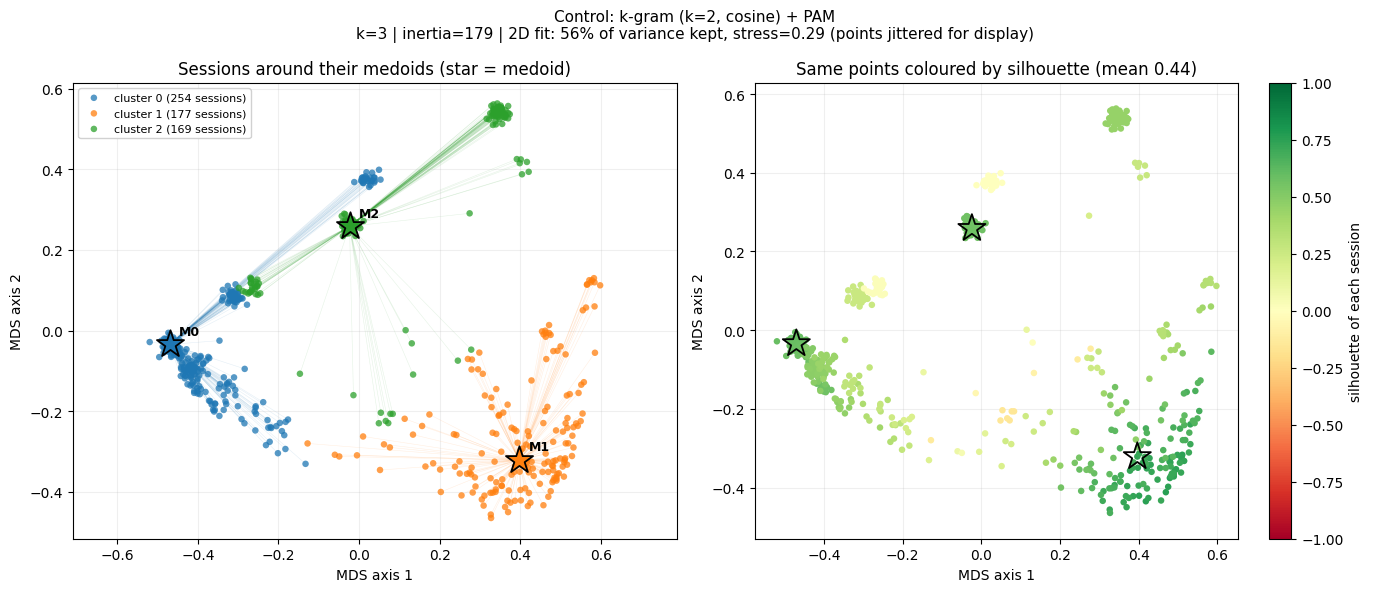

In [ ]:
tm = TransitionModel(k=2, metric="cosine").fit_kgrams(ctrl)
res = tm.cluster(3, "kmedoids")
print("ARI", round(adjusted_rand_index(tm.labels_, truth), 3), "| purity", round(cluster_purity(tm.labels_, truth), 3),
      "| silhouette", round(tm.silhouette_score(), 3))
print(pd.crosstab(pd.Series(truth, name="true"), pd.Series(tm.labels_, name="found")))
for c, (n, p) in enumerate(zip(res["sizes"], res["prototypes"])):
    print(f"cluster {c} ({n} sessions) prototype: {p}")
fig, _ = tm.plot_clusters(title="Control: k-gram (k=2, cosine) + PAM"); plt.show()

## 8. Head to head with Stage 1 (Levenshtein + PAM) on the same sessions
Same clustering algorithm, only the distance changes. We compare quality (ARI vs truth), agreement between the two clusterings, and the time to build the distance matrix.

In [ ]:
t0 = time.perf_counter(); al = BaselineAligner("levenshtein"); al.fit_distance_matrix(ctrl); t_lev = time.perf_counter() - t0
al.extract_prototypes(3)
t0 = time.perf_counter(); tm.fit_kgrams(ctrl); tm.fit_distance_matrix(); t_kg = time.perf_counter() - t0
tm.cluster(3, "kmedoids")

print(f"{'':22s}{'ARI vs truth':>14s}{'silhouette':>12s}{'matrix time':>13s}")
print(f"{'Levenshtein + PAM':22s}{adjusted_rand_index(al.labels_, truth):14.3f}{al.silhouette_score():12.3f}{t_lev:12.2f}s")
print(f"{'k-gram cosine + PAM':22s}{adjusted_rand_index(tm.labels_, truth):14.3f}{tm.silhouette_score():12.3f}{t_kg:12.2f}s")
print("agreement between the two clusterings (ARI):", round(adjusted_rand_index(al.labels_, tm.labels_), 3))

                        ARI vs truth  silhouette  matrix time
Levenshtein + PAM              0.609       0.489        7.78s
k-gram cosine + PAM            0.572       0.443        0.04s
agreement between the two clusterings (ARI): 0.451


## 9. Second clustering route: spherical k-means (no distance matrix)

In [ ]:
t0 = time.perf_counter()
tm_km = TransitionModel(k=2).fit_kgrams(ctrl)
tm_km.cluster(3, "kmeans", n_init=5, random_state=0)
t_km = time.perf_counter() - t0
print("distance matrix built:", tm_km.distance_matrix is not None, f"| time {t_km:.2f}s")
print("ARI vs truth", round(adjusted_rand_index(tm_km.labels_, truth), 3), "| agreement with k-medoids", round(adjusted_rand_index(tm_km.labels_, tm.labels_), 3))

distance matrix built: False | time 0.12s
ARI vs truth 0.603 | agreement with k-medoids 0.714


## 10. Markov chains: transition heatmaps per cluster
Rows = current event, columns = next event. All three heatmaps use the same rows, columns and colour scale, so they can be compared cell by cell. Each cluster should show its own dynamics (e.g. `product_view -> add_to_cart` in the buyer cluster).

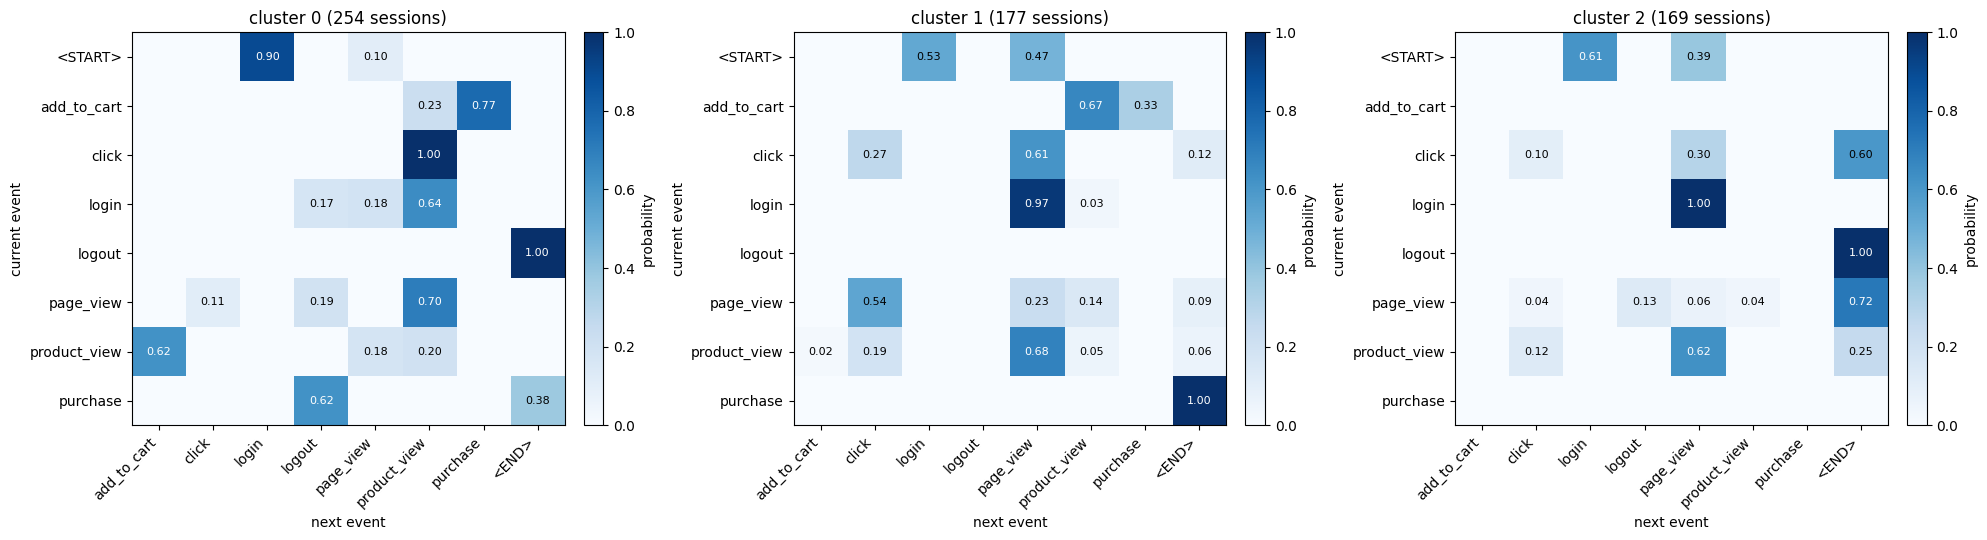

In [ ]:
tm.fit_markov_chain()
rows_ = [s for s in tm.states if s != END]          # same layout for every panel
cols_ = [s for s in tm.states if s != START]
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
for c, ax in enumerate(axes):
    plot_transition_matrix(tm.transition_matrix(c), tm.states, title=f"cluster {c} ({res['sizes'][c]} sessions)",
                           ax=ax, vmax=1.0, rows=rows_, cols=cols_)
plt.tight_layout(); plt.show()

## 11. Entry points and drop-off
`P(session ends right after this event)` per cluster. A high bar marks where users leave.

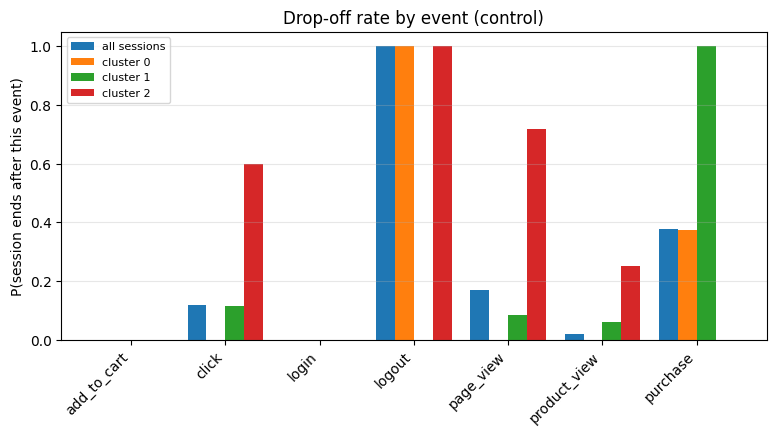

,cluster 0,cluster 1,cluster 2
entry event,,,
add_to_cart,0.0,0.00,0.00
click,0.0,0.00,0.00
login,0.9,0.53,0.61
logout,0.0,0.00,0.00
page_view,0.1,0.47,0.39
product_view,0.0,0.00,0.00
purchase,0.0,0.00,0.00


In [ ]:
rates = {"all sessions": tm.dropoff_rates()}
rates.update({f"cluster {c}": tm.dropoff_rates(c) for c in range(3)})
plot_dropoff_rates(rates, title="Drop-off rate by event (control)"); plt.show()
pd.DataFrame({f"cluster {c}": tm.entry_probabilities(c) for c in range(3)}).round(2).rename_axis("entry event")

## 12. Conversion bottlenecks
`P(session ever reaches purchase)` from each state (absorption probability of the chain). `<START>` is the expected share of sessions in the cluster that contain a purchase; we check it against the empirical share, which validates the Markov assumption.

In [ ]:
rows = []
for c in range(3):
    h = tm.conversion_probability("purchase", c)
    members = [s for s, l in zip(tm.sequences, tm.labels_) if l == c]
    rows.append({"cluster": c, "sessions": len(members),
                 "model P(purchase) from <START>": round(h[START], 3),
                 "empirical share with purchase": round(np.mean(["purchase" in s for s in members]), 3)})
display(pd.DataFrame(rows).set_index("cluster"))
pd.DataFrame({f"cluster {c}": tm.conversion_probability("purchase", c) for c in range(3)}).drop(index=[END, "purchase"]).round(2)   # the target row is 1 by definition, <END> is 0

,sessions,model P(purchase) from <START>,empirical share with purchase
cluster,,,
0,254,0.744,0.744
1,177,0.006,0.006
2,169,0.000,0.000


,cluster 0,cluster 1,cluster 2
<START>,0.74,0.01,0.0
add_to_cart,0.99,0.34,0.0
click,0.93,0.00,0.0
login,0.74,0.01,0.0
logout,0.00,0.00,0.0
page_view,0.76,0.01,0.0
product_view,0.93,0.01,0.0


## 13. Representative path (maximum log-likelihood, length >= median)
Compared with `min_len=1`, which shows why the bound exists: without it the "most probable" path collapses toward the shortest sessions (clearly visible for the browser cluster, whose typical sessions are long).

In [ ]:
for c in range(3):
    path, ll = tm.get_representative_path(c)
    short, ll_s = tm.get_representative_path(c, min_len=1)
    print(f"cluster {c}: {' > '.join(path)}   (log-lik {ll:.1f})")
    print(f"           min_len=1 : {' > '.join(short)}   (log-lik {ll_s:.1f})")

cluster 0: login > product_view > add_to_cart > purchase > logout   (log-lik -1.7)
           min_len=1 : login > product_view > add_to_cart > purchase > logout   (log-lik -1.7)
cluster 1: login > page_view > click > page_view > click > page_view > click > page_view > click > page_view   (log-lik -7.6)
           min_len=1 : login > page_view   (log-lik -3.1)
cluster 2: login > page_view   (log-lik -0.8)
           min_len=1 : login > page_view   (log-lik -0.8)


## 14. The real data (Experiment 2 scale: 5,000 sessions)
If the dataset has no behavioural structure, expect: silhouette near 0 and a global transition matrix with all rows close to uniform.

**Caveat (circularity).** Clusters are built from the same transitions that we then profile, so cluster chains will differ *by construction*, even on random data. To judge whether the differences mean anything, we compare them with the differences between **random partitions of the same sizes**.

5000 sessions, vocabulary 14 2-grams, time 6.0s
silhouette: 0.636 | cluster sizes: [2056 1228 1120  420  176]


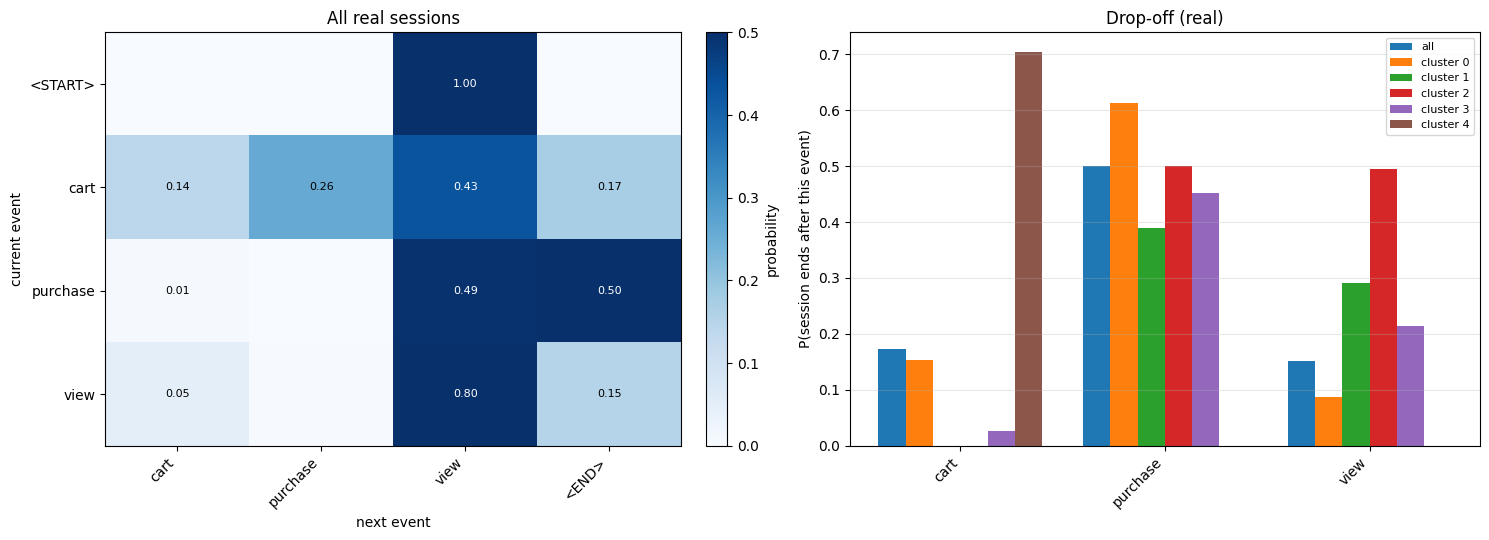

max transition-probability gap between clusters: found 0.85 | random partitions of the same sizes 0.21 (range 0.10-0.42)


In [ ]:
from journey_analyzer.transitions import build_states, count_transitions, normalize_transitions

rng_r = np.random.default_rng(42)
real = [sequences[i] for i in rng_r.choice(len(sequences), size=min(5000, len(sequences)), replace=False)]
t0 = time.perf_counter()
tm_real = TransitionModel(k=2).fit_kgrams(real)
rr = tm_real.cluster(5, "kmedoids"); tm_real.fit_markov_chain()
print(f"{len(real)} sessions, vocabulary {tm_real.kgram_matrix.shape[1]} 2-grams, time {time.perf_counter() - t0:.1f}s")
print("silhouette:", round(tm_real.silhouette_score(), 3), "| cluster sizes:", rr["sizes"])

fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
plot_transition_matrix(tm_real.transition_matrix(), tm_real.states, title="All real sessions", ax=ax[0], vmax=0.5)
plot_dropoff_rates({"all": tm_real.dropoff_rates(), **{f"cluster {c}": tm_real.dropoff_rates(c) for c in range(5)}}, ax=ax[1], title="Drop-off (real)")
plt.tight_layout(); plt.show()

states_r = tm_real.states
def max_spread(groups):
    # largest gap, over all transitions, between the highest and lowest group probability
    Ps = [normalize_transitions(count_transitions(g, states_r), states_r) for g in groups]
    return float((np.max(Ps, axis=0) - np.min(Ps, axis=0)).max())

found = [[s for s, l in zip(real, tm_real.labels_) if l == c] for c in range(5)]
rng_n = np.random.default_rng(0)
null = []
for _ in range(20):
    perm = rng_n.permutation(tm_real.labels_)
    null.append(max_spread([[s for s, l in zip(real, perm) if l == c] for c in range(5)]))
print(f"max transition-probability gap between clusters: found {max_spread(found):.2f} | "
      f"random partitions of the same sizes {np.mean(null):.2f} (range {min(null):.2f}-{max(null):.2f})")

## 15. Scalability: where the N x N matrix stops being an option
k-gram distances are much cheaper than Levenshtein, but both need an N x N matrix. Spherical k-means on the sparse vectors does not.

In [ ]:
rows = []
for n in (250, 500, 1000, 2000, 4000):
    sub = [sequences[i] for i in np.random.default_rng(1).choice(len(sequences), n, replace=False)]
    t0 = time.perf_counter(); TransitionModel(k=2).fit_kgrams(sub).fit_distance_matrix(); t_kg = time.perf_counter() - t0
    t_lev = np.nan
    if n <= 1000:
        t0 = time.perf_counter(); BaselineAligner().fit_distance_matrix(sub); t_lev = time.perf_counter() - t0
    rows.append({"N": n, "k-gram matrix (s)": round(t_kg, 2), "Levenshtein matrix (s)": round(t_lev, 2) if t_lev == t_lev else "skipped (slow)",
                 "matrix size (MB)": round(4 * n * n / 1e6, 1)})
display(pd.DataFrame(rows).set_index("N"))

big = [sequences[i] for i in np.random.default_rng(2).integers(0, len(sequences), 50_000)]     # bootstrap to 50,000 sessions
t0 = time.perf_counter()
tm_big = TransitionModel(k=2).fit_kgrams(big)
tm_big.cluster(5, "kmeans", n_init=2, random_state=0)
print(f"50,000 sessions clustered with spherical k-means in {time.perf_counter() - t0:.1f}s without any N x N matrix "
      f"(that matrix alone would need {4 * 50_000**2 / 1e9:.0f} GB)")
try:
    tm_big.fit_distance_matrix()
except MemoryError as e:
    print("MemoryError:", e)

,k-gram matrix (s),Levenshtein matrix (s),matrix size (MB)
N,,,
250,0.03,1.21,0.2
500,0.03,6.96,1.0
1000,0.09,23.3,4.0
2000,0.43,skipped (slow),16.0
4000,1.27,skipped (slow),64.0


50,000 sessions clustered with spherical k-means in 1.4s without any N x N matrix (that matrix alone would need 10 GB)
MemoryError: A 50000 x 50000 float32 distance matrix needs ~10.0 GB (limit 4.0 GB). Cluster the k-gram vectors directly with spherical k-means instead (no N x N matrix).


## Conclusions

Stage 2 doesn’t improve cluster quality over exact alignment. It trades some global order information for linear-time representation, matrix-free clustering and interpretable transition profiles. On controls, quality is within 0.04 ARI, and the cost difference grows with N.


- **Validity:** on the control data, ARI vs the planted groups shows whether each representation recovers known structure; the real data is judged against that reference.
- **Representation comparison:** Levenshtein (Stage 1) vs k-gram cosine (Stage 2) on identical sessions and the same PAM algorithm; differences are due to the distance only.
- **Scalability:** matrix time and size by N; spherical k-means as the route that avoids the N^2 wall.
- **Interpretability:** heatmaps, drop-off, absorption probability and the representative path give readable explanations that the distance matrix alone does not.
- **Limits to state:** first-order memorylessness, local order only (window k), sensitivity to k, the cosine non-metric caveat, and that representative paths may not exist in the data.